# EX10: Implement PageRank 

## Overview
In this notebook, you will implement the **PageRank** algorithm.

You will break the work into small steps:
1. Load a graph
2. Construct the transition model
3. Implement PageRank via power iteration
4. Validate with sanity checks
5. Analyze results (top nodes, distribution, sensitivity)

You should have a more intuitive understanding of PageRank after completing the assignment.

You may use `numpy` and `matplotlib` for computations and plots.

**Do not** use `networkx.pagerank` or any other built-in PageRank implementation.


In [1]:
import numpy as np 
import networkx as nx 
import pylab as plot
import pandas as pd

## 1. Load the graph 


Included in the repository is a file `epl_final.csv`. This is a record of all matches in the English Premier League from 2000 - 2025. 

Load the csv with Pandas and transform the data into a graph. You should 
- Filter the dataframe to only matches that occured in the 2024/2025 season. 
- Add a vertex for every unique team
- Add a directed edge A -> B if team B won against team A. 

In [16]:
df = pd.read_csv("epl_final.csv")

# your code here
df = df[df["Season"]=="2024/25"]
print(len(df))

G = nx.DiGraph()
G.add_nodes_from(df["HomeTeam"])

print(G.number_of_nodes())

for idx, row in df.iterrows():
    result = row["FullTimeResult"]
    if result == "H":
        G.add_edge(row["AwayTeam"], row["HomeTeam"])
    if result == "A":
        G.add_edge(row["HomeTeam"], row["AwayTeam"])
    # if result == D?

350
20


## 2. Build the transition matrix

Write a function which takes a networkX graph, and constructs the transition matrix from the graph. Recall that the transition matrix is defined as

$$
\{P_{ij}\} = 
\begin{cases}
\frac{1}{outdeg(v_i)} & (i,j) \in E \\ 
\frac{1}{n} & outdeg(v_i) = 0 \\
0 & \text{otherwise}
\end{cases}
$$

In [24]:
# Your code here 
def buildTransitionMatrix(G):
    teams = list(G.nodes())
    n = len(teams)
    P = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            if G.has_edge(teams[i], teams[j]):
                P[i][j] = 1/ G.out_degree(teams[i])
            elif G.out_degree(teams[i]) == 0:
                P[i][j] = 1/n
            else:
                P[i][j] = 0
    return P
                

# 2.5 Build the full transition matrix (with teleportation)

Recall the matrix actually used in PageRank is the following 
$$
P' = dP + (1-d) \frac{1}{n}J
$$
Where $J$ is the $n \times n$ matrix of all ones. And $d$ is a *damping factor*, a hyperparameter which controls the probablility a teleportation occurs.

In [28]:
# Your code here
def buildFullMatrix(G,d=0.85):
    teams = list(G.nodes())
    n = len(teams)
    J = np.ones((n, n))
    P = buildTransitionMatrix(G)
    return d * P + (1 - d) * (1/n) * J

# 3. PageRank Dense Matrix
Write a function which computes the PageRank of the graph explicitly, through iteration. 

Recall that if the PageRank approximation at step $t$ is $r_t$, 
$$
r_{t+1} = (P')^T r_t
$$

Update $r$ each iteration until either 
- $||r_{t+1} - r_t ||_1 \leq tol$ 
- $t > max\_iter$

In [35]:
def dist(a, b):
    # L1 distance
    return np.sum(np.abs(a - b))

def PageRank(G, d=0.85, tol=1e-6, max_iter=200):
    P_prime = buildFullMatrix(G, d)

    n = len(G.nodes())
    
    r = np.ones(n) / n
    diff = np.inf
    t = 0

    while not (t > (max_iter) or diff <= tol):
        r_next = P_prime.T @ r
        diff = dist(r_next, r)
        r = r_next
        t += 1

    return r
    



r = PageRank(G)

print(f"Sum of entries is {np.sum(r)}, should be close to zero.") # but mine is close to 1

Sum of entries is 1.0000000000000002, should be close to zero.


## 3.5 Check against networkx implementation


In [38]:
r_networkx = nx.pagerank(G)

r_nx_arr = np.array([r_networkx[v] for v in G.nodes()])

np.all(np.isclose(r_nx_arr,r))

np.True_

## 4. PageRank Sparse Iteration
Of course, the real cleverness in PageRank is the insight that you don't need to explictly construct the full matrix, by exploiting this is a graph problem. Use the starter code below to complete a function which performs a single step of PageRank without the dense matrix.

In [53]:
def pagerank_step(G,r,d=0.85): 
    n = G.number_of_nodes()
    r_next = np.zeros(n,dtype=np.float32)

    #Fill all entries in r_next with the teleportation weights

    r_next += np.full((n,), (1-d)/n)


    #Then, iterate over all vertices 
    #Propagate each vertex influence to its out-neighbors. 
    #Vertices with outdegree 0 should be handled differently.
    idx_dict = {v: i for i, v in enumerate(G.nodes())}

    for i, v in enumerate(G.nodes()):
        if G.out_degree(v) == 0:
            r_next += np.full((n,), d * r[i] /n)
        else:
            for suc in G.successors(v):
                r_next[idx_dict[suc]] += d * r[i] / G.out_degree(v)

    return r_next

## 4.5 PageRank Sparse Power Iteration
Again, write a function which iteratively updates a vector until convergence

In [54]:
def PageRank_Sparse(G,d=0.85, tol=1e-6, max_iter=200):
    n = G.number_of_nodes()
    r = np.ones(n) / n

    diff = np.inf
    t = 0

    while not (t > (max_iter) or diff <= tol):
        r_next = pagerank_step(G, r, d)
        diff = dist(r_next, r)
        r = r_next
        t += 1

    return r

Again, do a small sanity check against your previous and networkx implmentation.

In [57]:
# your code here
r_sparse = PageRank_Sparse(G)
r_dense = PageRank(G)
r_networkx = nx.pagerank(G)
r_nx_arr = np.array([r_networkx[v] for v in G.nodes()])

print(np.all(np.isclose(r_nx_arr,r_sparse)))
print(np.all(np.isclose(r_dense,r_sparse)))

True
True


## Sparse vs. Full 
You should conduct the below results on the `Wiki-Vote.txt` data (edgelist). This data includes a directed edge A -> B if user A voted to promote user B to an admin role on Wikipedia.

You can verify that such a large graph will be very slow (or even run out of memory) on the full dense matrix implementation.

## 5. Results: top nodes by PageRank

### Task
- Print the top-10 nodes by PageRank score
- Include their scores

Write a short 2-3 sentences on how these scores can be interpreted in your data.


In [74]:
G_wiki = nx.read_edgelist("Wiki-Vote.txt", create_using=nx.DiGraph, nodetype=int)

r_wiki = PageRank_Sparse(G_wiki)
zipped = zip(r_wiki, list(G_wiki.nodes()), )
scores = sorted(zipped, reverse=True)[:10]
scores_reversed = [(pair[1], pair[0]) for pair in scores]
scores_formatted = [{"ID": (pair[0]), "score": float(pair[1])} for pair in scores_reversed]
scores_formatted

[{'ID': 4037, 'score': 0.004607182927429676},
 {'ID': 15, 'score': 0.003679867833852768},
 {'ID': 6634, 'score': 0.0035867856349796057},
 {'ID': 2625, 'score': 0.003283663187175989},
 {'ID': 2398, 'score': 0.0026086359284818172},
 {'ID': 2470, 'score': 0.0025237733498215675},
 {'ID': 2237, 'score': 0.002496630884706974},
 {'ID': 4191, 'score': 0.0022678535897284746},
 {'ID': 7553, 'score': 0.002169730607420206},
 {'ID': 5254, 'score': 0.0021501018200069666}]

**your interpretation** <br>
4037 has the most support and is supported by people who are also popular, next comes 12, then 6634, ...

## 6. Light analysis

### 6.1 Distribution of PageRank scores
Plot a histogram of PageRank scores.

Questions to answer:
- Is the distribution highly skewed? A: Yes. Very.
- Do most nodes have very small score? A: Yes.


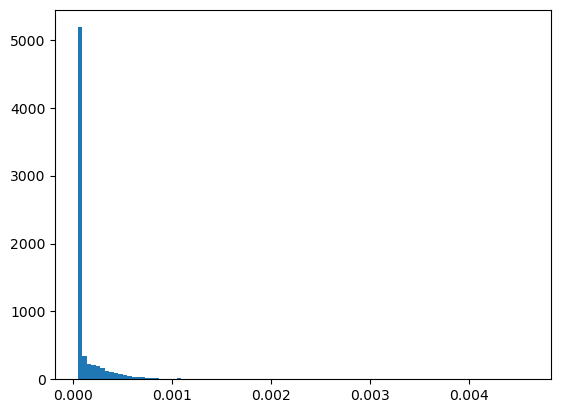

In [78]:
import matplotlib.pyplot as plt

plt.hist(r_wiki, bins=100)
plt.show()

### 6.2 Compare damping factors

Run PageRank with different damping factors and compare:
- `d = 0.70`, `0.85`, `0.95`

Tasks:
1. Compute rank vectors for each `d`
2. Compare the **top-10 overlap** between settings
3. Compute L1 distances between the resulting rank vectors

Answer briefly:
- Which nodes are stable across damping factors? A: The top 10 nodes are mostly stable, except 7553 and 1186
- Does higher `d` concentrate more probability on a smaller set of nodes? A: Higher `d` concentrated on the top10.


In [97]:
def top10(r, G, is_only_id=False):
    # return list of IDs only
    zipped = zip(r, list(G.nodes()), )
    scores_top10 = sorted(zipped, reverse=True)[:10]
    if is_only_id:
        return [pair[1] for pair in scores_top10]
    else:
        return [{"ID": (pair[1]), "score": float(pair[0])} for pair in scores_top10]
    
# 1.
r_70 = PageRank_Sparse(G_wiki, d=0.70)
r_85 = PageRank_Sparse(G_wiki, d=0.85)
r_95 = PageRank_Sparse(G_wiki, d=0.95)

# 2.
set_r_70 = set(top10(r_70, G_wiki, is_only_id=True))
set_r_85 = set(top10(r_85, G_wiki, is_only_id=True))
set_r_95 = set(top10(r_95, G_wiki, is_only_id=True))
print("Nodes top 10")
print("d=0.70, top10:", set_r_70)
print("d=0.85, top10:", set_r_85)
print("d=0.95, top10:", set_r_95)
# source: https://stackoverflow.com/questions/12789820/intersection-of-three-sets-in-python
overlap = (set_r_70 & set_r_85 & set_r_95)
print(f"Overlap: {overlap}; contains {len(overlap)} out of 10") 
print()

# 3.
print("L1 distances for rank vectors:")
print("Between d=0.70 and d=0.85:", dist(r_70, r_85))
print("Between d=0.95 and d=0.85:", dist(r_95, r_85))
print("Between d=0.70 and d=0.95:", dist(r_70, r_95))
print()

# to answer "Does higher `d` concentrate more probability on a smaller set of nodes?"
top_10_sum_r_70 = sum([node_score_pair["score"] for node_score_pair in top10(r_70, G_wiki)])
top_10_sum_r_85 = sum([node_score_pair["score"] for node_score_pair in top10(r_85, G_wiki)])
top_10_sum_r_95 = sum([node_score_pair["score"] for node_score_pair in top10(r_95, G_wiki)])
print(f"for d=0.70, top 10's probability occupy {top_10_sum_r_70} out of 1")
print(f"for d=0.85, top 10's probability occupy {top_10_sum_r_85} out of 1")
print(f"for d=0.95, top 10's probability occupy {top_10_sum_r_95} out of 1")

Nodes top 10
d=0.70, top10: {2625, 1186, 4037, 2470, 5254, 6634, 15, 2237, 2398, 4191}
d=0.85, top10: {2625, 7553, 4037, 2470, 5254, 6634, 15, 2237, 2398, 4191}
d=0.95, top10: {2625, 7553, 4037, 2470, 5254, 6634, 15, 2237, 2398, 4191}
Overlap: {2625, 4037, 2470, 5254, 6634, 15, 2237, 2398, 4191}; contains 9 out of 10

L1 distances for rank vectors:
Between d=0.70 and d=0.85: 0.151647
Between d=0.95 and d=0.85: 0.101637945
Between d=0.70 and d=0.95: 0.25267

for d=0.70, top 10's probability occupy 0.025816078181378543 out of 1
for d=0.85, top 10's probability occupy 0.029374225763604045 out of 1
for d=0.95, top 10's probability occupy 0.03172625578008592 out of 1


### 6.3 Relationship with out-degree

Compute correlation between PageRank and out-degree.

Questions:
- Are high PageRank nodes necessarily high out-degree nodes? A: No.
- What do you observe in the scatter plot? A: A lot of points are clustered in the bottom-left corner


PageRank vector: [1.7287233e-04 8.1436511e-04 1.7839578e-03 ... 5.0488423e-05 5.0488423e-05
 5.0488423e-05], shape=(7115,)
Out-degree vector: [  5   0 273 ...   1   2   1], shape=(7115,)
corr: 0.2538058158558775


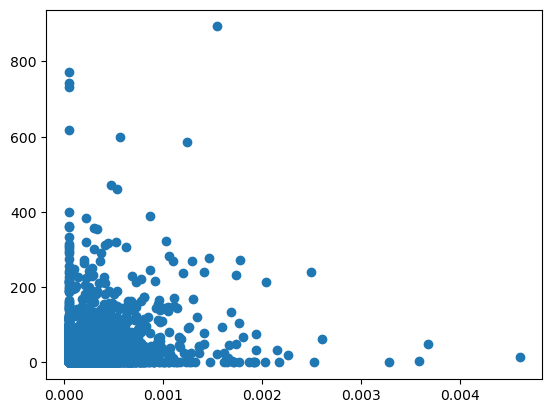

In [114]:
nodes = list(G_wiki.nodes())
nodes_from_out_degree = [node for (node, out_deg) in dict(G_wiki.out_degree()).items()]
assert nodes == nodes_from_out_degree

out_degrees = np.array([out_deg for (node, out_deg) in dict(G_wiki.out_degree()).items()])

print(f"PageRank vector: {r_wiki}, shape={r_wiki.shape}")
print(f"Out-degree vector: {out_degrees}, shape={out_degrees.shape}")

print("corr:", np.corrcoef(r_wiki, out_degrees)[0, 1])
plt.scatter(r_wiki, out_degrees)
plt.show()

In [106]:
dict(G_wiki.out_degree()).items()

dict_items([(30, 5), (1412, 0), (3352, 273), (5254, 33), (5543, 137), (7478, 0), (3, 23), (28, 133), (39, 41), (54, 7), (108, 2), (152, 21), (178, 63), (182, 79), (214, 0), (271, 0), (286, 0), (300, 0), (348, 21), (349, 1), (371, 117), (567, 2), (581, 0), (584, 5), (586, 13), (590, 8), (604, 8), (611, 0), (8283, 0), (25, 90), (6, 302), (8, 182), (19, 39), (23, 74), (29, 150), (33, 24), (35, 65), (50, 14), (55, 64), (75, 31), (80, 59), (86, 122), (94, 80), (127, 132), (154, 61), (192, 19), (224, 13), (226, 25), (246, 1), (252, 0), (255, 86), (257, 8), (261, 8), (273, 7), (280, 76), (282, 39), (299, 0), (302, 13), (306, 244), (308, 142), (310, 230), (322, 0), (325, 25), (339, 80), (356, 18), (358, 0), (363, 3), (370, 0), (373, 0), (377, 0), (379, 0), (407, 145), (415, 4), (422, 0), (428, 0), (439, 8), (488, 4), (514, 0), (545, 24), (549, 4), (560, 8), (592, 12), (600, 214), (645, 16), (650, 98), (659, 14), (664, 13), (667, 19), (673, 5), (675, 1), (696, 6), (706, 95), (723, 1), (739, 0),